In [2]:
import pandas as pd
import numpy as np

data = {
    "Study_Hours": [2, 3, 4, 5, 6, 7, 8, 9],
    "Attendance": [60, 65, 70, 75, 80, 85, 90, 95],
    "Previous_Marks": [50, 55, 60, 65, 70, 75, 80, 85],
    "Sleep_Hours": [8, 7, 8, 6, 7, 8, 6, 7],
    "Student_ID": [101, 102, 103, 104, 105, 106, 107, 108],
    "Performance": [45, 50, 55, 65, 70, 75, 85, 90]
}

df = pd.DataFrame(data)

print(df)

   Study_Hours  Attendance  Previous_Marks  Sleep_Hours  Student_ID  \
0            2          60              50            8         101   
1            3          65              55            7         102   
2            4          70              60            8         103   
3            5          75              65            6         104   
4            6          80              70            7         105   
5            7          85              75            8         106   
6            8          90              80            6         107   
7            9          95              85            7         108   

   Performance  
0           45  
1           50  
2           55  
3           65  
4           70  
5           75  
6           85  
7           90  


In [4]:
X = df.drop("Performance", axis=1)
y = df["Performance"]

print("Input Feature: ")
print(X.head())

print("\nTarget: ")
print(y.head())

Input Feature: 
   Study_Hours  Attendance  Previous_Marks  Sleep_Hours  Student_ID
0            2          60              50            8         101
1            3          65              55            7         102
2            4          70              60            8         103
3            5          75              65            6         104
4            6          80              70            7         105

Target: 
0    45
1    50
2    55
3    65
4    70
Name: Performance, dtype: int64


In [7]:
from sklearn.feature_selection import VarianceThreshold

selector = VarianceThreshold(threshold=0)

X_selected = selector.fit_transform(X)

selected_features = X.columns[selector.get_support()]

print("Selected features: ")
print(selected_features.tolist())

print("\nSelected Data : ")
print(pd.DataFrame(X_selected,columns=selected_features))

Selected features: 
['Study_Hours', 'Attendance', 'Previous_Marks', 'Sleep_Hours', 'Student_ID']

Selected Data : 
   Study_Hours  Attendance  Previous_Marks  Sleep_Hours  Student_ID
0            2          60              50            8         101
1            3          65              55            7         102
2            4          70              60            8         103
3            5          75              65            6         104
4            6          80              70            7         105
5            7          85              75            8         106
6            8          90              80            6         107
7            9          95              85            7         108


In [11]:
X_test = X.copy()

X_test["Constant_feature"] = [1, 1, 1, 1, 1, 1, 1, 1]

selector = VarianceThreshold(threshold=0)

X_test_selected = selector.fit_transform(X_test)

selected_features = X_test.columns[selector.get_support()]

print("Selected features: ")
print(selected_features.tolist())

Selected features: 
['Study_Hours', 'Attendance', 'Previous_Marks', 'Sleep_Hours', 'Student_ID']


In [13]:
correlation = df.corr(numeric_only=True)

print(correlation["Performance"].sort_values(ascending=False))

Performance       1.000000
Study_Hours       0.996368
Attendance        0.996368
Previous_Marks    0.996368
Student_ID        0.996368
Sleep_Hours      -0.441315
Name: Performance, dtype: float64


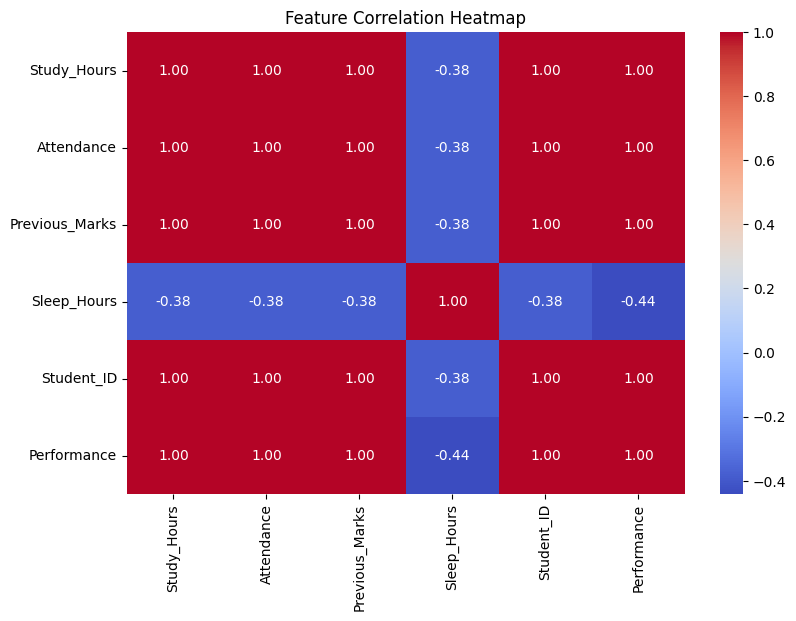

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [17]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression

model = LinearRegression()

selector = RFE(
    estimator=model,
    n_features_to_select=3
)

selector.fit(X, y)

print("Selected Features:")
print(X.columns[selector.support_].tolist())

print("\nFeature Rankings:")
print(pd.DataFrame({
    "Feature": X.columns,
    "Ranking": selector.ranking_
}))

Selected Features:
['Attendance', 'Previous_Marks', 'Sleep_Hours']

Feature Rankings:
          Feature  Ranking
0     Study_Hours        3
1      Attendance        1
2  Previous_Marks        1
3     Sleep_Hours        1
4      Student_ID        2


In [19]:
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=0.1)

lasso.fit(X, y)

print("Feature Coefficients:")

for feature, coefficient in zip(X.columns, lasso.coef_):
    print(feature, ":", coefficient)

Feature Coefficients:
Study_Hours : 0.0
Attendance : 1.2906819484240686
Previous_Marks : 0.0
Sleep_Hours : -1.1448710601719205
Student_ID : 0.0


In [20]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf.fit(X, y)

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

          Feature  Importance
0     Study_Hours    0.278858
4      Student_ID    0.246134
1      Attendance    0.240272
2  Previous_Marks    0.200367
3     Sleep_Hours    0.034369
